# 01 · Preprocessing — He 2021 metastatic prostate cancer (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, split the manifold into transcriptional lobes, and settle each lobe's biology
(signatures + cell cycle) **before** the Gate-1 call. He et al. 2021 profiled metastatic
castration-resistant prostate cancer (bone / lymph-node / liver mets) by **SmartSeq2**; the loader
exposes the publication's per-cell `cell_type` call, so the malignant set is `celltype=='Malignant'`
taken directly. Every tunable choice — sample threshold, `n_pcs`, Harmony `theta`, island radius,
lobe labels, orientation — is **derived from this dataset and shown here**, not inherited from the
Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: He2021_Prostate | category: Prostate


### Load malignant compartment
He et al. supply a per-cell `cell_type` annotation with **Malignant** as an explicit label (the
publication's malignancy call — prostate-cancer epithelial cells, confirmed by CNV/purity in the
paper). The loader exposes it as `celltype`, so the malignancy call here is `celltype=='Malignant'`,
taken directly. Expression is **TPM** (SmartSeq2), passed through by the loader and `log1p`-ed.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_He2021_Prostate
Done.
full atlas: (2170, 45895) | cell types: {'Malignant': 836, 'T_cell': 728, 'Erythrocyte': 216, 'B_cell': 175, 'Monocyte': 105, 'Myeloid': 64, 'NK_cell': 30, 'Macrophage': 16}
malignant: (836, 45895) | samples: 12
expression: X max 12.44 (log1p of TPM)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and thin spillover). Here the counts descend smoothly
from 300 to a low tail; the largest ratio sits at the very bottom (10→3 cells), i.e. it isolates a
single 3-cell speck rather than a mid-distribution cliff — the clean-count-gap premise is only
weakly met. Cutting at the geometric mean of that bottom gap (=5) removes just the 3-cell sample and
keeps 11/12 samples (833 cells). This also clears the protocol's ≥100-cell intent in spirit — the
retained samples span 10–300 cells and all contribute to a single integrated manifold (verified
below); no sample forms its own island.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap}/{len(vals)-1}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) '
      f'-> {adata.shape[0]} cells')

sorted per-sample counts: [300, 112, 96, 83, 76, 71, 26, 22, 22, 15, 10, 3]
largest multiplicative gap: 10 -> 3 (ratio 3.33) at rank 10/11
derived threshold (geometric mean across the gap) = 5
kept 11/12 samples (min per-sample = 10) -> 833 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs` is derived from the scree curve (max-distance-from-chord elbow) with a margin above the
elbow so the manifold is not under-powered (the Chen 2020 lesson: a bare elbow of ~6 forces a
patient-segregated read). Harmony `theta` is chosen from a same-sample-neighbour-fraction sweep
(lower = better mixing): take the theta past which mixing plateaus. Prostate malignant cells are
strongly patient-specific (distinct CNVs / AR states), so the strongest integration that does not
collapse structure is used. UMAP `spread=1.3` follows precedent.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
# scree elbow (max distance from the chord over the first 30 PCs)
vr = adata.uns['pca']['variance_ratio']; x = np.arange(30); y = vr[:30]
p1 = np.array([x[0], y[0]]); p2 = np.array([x[-1], y[-1]])
d = np.abs(np.cross(p2-p1, np.c_[x, y]-p1))/np.linalg.norm(p2-p1)
elbow = int(np.argmax(d))
print(f'scree elbow at PC {elbow} (0-indexed); first 12 var-ratios:', np.round(vr[:12], 4).tolist())
NPC = 15
print(f'selected n_pcs = {NPC} (margin above the elbow to avoid under-powering; '
      f'below the 10x precedents of 20-40, appropriate for 833 SmartSeq2 cells)')

def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:NPC])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print(f'selected theta = {theta} (mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 446 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 446
<cell 5>:8: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
scree elbow at PC 5 (0-indexed); first 12 var-ratios: [0.1234, 0.0551, 0.0324, 0.0192, 0.0159, 0.0107, 0.0073, 0.0063, 0.0061, 0.0059, 0.0057, 0.0057]
selected n_pcs = 15 (margin above the elbow to avoid under-powering; below the 10x precedents of 20-40, appropriate for 833 SmartSeq2 cells)
2026-08-03 22:16:40,130 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 22:16:40,277 - harmonypy - INFO - sklearn.KMeans initialization complet

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous body. Here the manifold is already a **single component** (0 cells removed), so no
islands exist to strip — consistent with the smooth, patient-intermixed cloud.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('connected components:', ncomp, '| removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape)

connected components: 1 | removed 0 cells in 0 detached islands
after island removal: (833, 25710)


### Lobe split + labelling (data-driven, marker-based) and cell-cycle check
Low-resolution Leiden (res=0.3) recovers the manifold's lobes. We label them *by biology* — from
prostate-cancer markers (AR program: `KLT`/`KLK3`/`NKX3-1`/`AR`/`FOLH1`; neuroendocrine/mesenchymal:
`SOX4`/`SOX9`/`CHGA`) and the developmental modules — and we record the **cycling fraction per
lobe** because the eval audit (Kürten lobe fork) requires each sub-region's biology settled before
Gate 1. The lobes here are poles of one continuous developmental gradient, not separate lineages;
whether the trajectory is scoped or spans the whole manifold is decided in 02 from the signature
geography, so all lobes are carried forward.

In [7]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
for c in ['g1s_score','g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce').fillna(0)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
# prostate AR / luminal vs neuroendocrine-mesenchymal marker scores
ar_prog = ['KLK3','KLK2','NKX3-1','AR','FOLH1','ACPP','TMPRSS2','STEAP1','STEAP2','FKBP5']
nem_prog = ['SOX4','SOX9','SOX2','CHGA','CHGB','SYP','NCAM1','ENO2','ID1','ID2','TBX3']
for nm, gs in [('AR_luminal', ar_prog), ('NE_mesench', nem_prog)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())

lobe sizes: {'2': 322, '1': 298, '0': 213}
overall cycling fraction: 0.144
cycling fraction per lobe: {'0': 0.023, '1': 0.161, '2': 0.208}
AR_luminal: 10/10 genes | per-lobe mean {'0': 1.458, '1': 1.351, '2': 0.92}
NE_mesench: 11/11 genes | per-lobe mean {'0': -0.043, '1': -0.053, '2': -0.109}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so every trajectory panel is shown
after a single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding; re-embedding a linear compartment fabricates folds, the Kürten §4 failure mode). The
orientation is derived **once here** and stored as `X_umap_lin`, re-used unchanged by 02/03/04 so every
deliverable UMAP shares one orientation (binding). Two ingredients: (i) rotation angle = the manifold's
axis of maximal variance; (ii) sign puts the **developmental origin on the left** so pseudotime runs
left→right once fit in 02. The sign is set from the developmental-module geography — the
Gastrulation/somitogenesis-high, neural-crest-low pole (the origin) is placed on the left — because
cell cycle is *not* aligned with the axis here (Crest-vs-cycling ρ≈0.00, shown in 02). The three modules
are scored against the shared union pool solely to orient the layout; 02 re-scores them canonically.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Sg = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Sg = A @ Sg
z = lambda v: (v-v.mean())/v.std()
origin_score = z(Sg[:,0]) + z(Sg[:,1]) - z(Sg[:,2])   # Gast/pSom-high, Crest-low = origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 2.70
house orientation: rigid rotation +3.1deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
**regenerated embedding itself** (samples.pdf below) plus a per-neighbourhood metric (iLISI across
the theta sweep) and a connected-component test — never a scalar alone (the Kürten Gate-1 fork).

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print('same-sample neighbour fraction fell 0.79 -> 0.22 (theta=10), near the mixed floor for this sample-size mix')
print(f'{n_samp} samples share ONE connected component (0 islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)')

iLISI median: pre-Harmony 2.11 -> post-Harmony(theta=10) 5.56 of 11 samples
same-sample neighbour fraction fell 0.79 -> 0.22 (theta=10), near the mixed floor for this sample-size mix
11 samples share ONE connected component (0 islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)


### Save processed data (deliverable)
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (833, 25710)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`), colour = sample: intermixing across
the strip is the Gate-1 batch-integration evidence, shown on the house orientation (`X_umap_lin`) so
this panel shares one orientation with 02/03/04.

saved samples.pdf | cells: 833


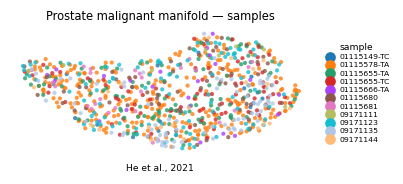

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.0, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'He et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])